# Лабораторная работа 2. Спектральная теория случайных матриц
### От иллюзии шума к диагностике нейросетей

**Структура:**
1. Задание 1 — шумовой балк Марченко–Пастура (режимы $\gamma = 0.5$ и $\gamma = 2$).
2. Задание 2 — фазовый переход BBP: где PCA «слепнет» и как откалибровать оценку сигнала.
3. Задание 3 — спектральная диагностика слоёв ResNet-18 по теории Мартина–Махони (HTSR).

Подробное объяснение всех понятий — в файле `ОБЪЯСНЕНИЕ.md` рядом с ноутбуком.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse.linalg import svds

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)

---
## Задание 1. Синтетический тест: шумовой балк Марченко–Пастура

Теория: для $X \in \mathbb{R}^{p\times n}$, $X_{ij}\sim\mathcal N(0,\sigma^2)$ и $\hat\Sigma = \frac1n XX^T$ при $p/n\to\gamma$
спектр сходится к закону Марченко–Пастура с плотностью

$$\rho_{MP}(\lambda)=\frac{\sqrt{(\lambda_+-\lambda)(\lambda-\lambda_-)}}{2\pi\sigma^2\gamma\lambda},\qquad \lambda_\pm=\sigma^2(1\pm\sqrt\gamma)^2 .$$

### 1.1. Генерация данных и спектр

In [2]:
def white_noise_spectrum(p, n, sigma2=1.0, rng=rng):
    # Спектр выборочной ковариации 1/n * X X^T для белого шума X (p x n)
    X = rng.normal(0.0, np.sqrt(sigma2), size=(p, n))
    cov = X @ X.T / n
    return np.linalg.eigvalsh(cov)  # симметричная матрица -> eigvalsh, по возрастанию


def mp_edges(gamma, sigma2=1.0):
    return sigma2 * (1 - np.sqrt(gamma)) ** 2, sigma2 * (1 + np.sqrt(gamma)) ** 2


def mp_density(lam, gamma, sigma2=1.0):
    # Непрерывная часть закона МП (без дельта-массы в нуле)
    lam_minus, lam_plus = mp_edges(gamma, sigma2)
    lam = np.asarray(lam, dtype=float)
    inside = (lam > lam_minus) & (lam < lam_plus)
    rho = np.zeros_like(lam)
    l = lam[inside]
    rho[inside] = np.sqrt((lam_plus - l) * (l - lam_minus)) / (2 * np.pi * sigma2 * gamma * l)
    return rho


def zero_threshold(eigs, shape):
    # Машинный ноль: стандартный допуск ранга (как в numpy.linalg.matrix_rank)
    return np.abs(eigs).max() * max(shape) * np.finfo(eigs.dtype).eps

### 1.2. Эксперимент в двух режимах ($n = 1000$)

**Порог отсечения нулей.** Сравнивать `eigs > 0` нельзя: из-за ошибок округления $p-n$ «нулевых» собственных чисел
выходят величинами порядка $\pm10^{-15}$. Берём стандартный допуск численного ранга
$\text{tol} = \lambda_{\max}\cdot\max(p,n)\cdot\varepsilon_{\text{machine}}$ ($\varepsilon \approx 2.2\cdot10^{-16}$), т.е. $\sim10^{-12}$.
Он на много порядков выше машинного шума и на много порядков ниже $\lambda_-\approx0.17$ — информативную часть спектра не задевает.

**Масштабный множитель для режима B ($\gamma>1$).** Полная мера МП:
$d\mu_{MP} = (1-\tfrac1\gamma)^+\delta_0 + \rho_{MP}\,d\lambda$ и нормирована на 1. Значит при $\gamma > 1$
$$\int_{\lambda_-}^{\lambda_+}\rho_{MP}(\lambda)\,d\lambda = 1-\Big(1-\frac1\gamma\Big)=\frac1\gamma = \frac np .$$
Это ровно доля ненулевых собственных чисел ($n$ из $p$). Гистограмма с `density=True`, построенная только по ненулевым,
интегрируется в **1**. Чтобы сравнивать с ней, теорию надо привести к условному распределению «при условии $\lambda\neq0$»:
$$\rho_{\text{cond}}(\lambda)=\frac{\rho_{MP}(\lambda)}{\int\rho_{MP}}=\gamma\cdot\rho_{MP}(\lambda).$$
Множитель $\gamma=2$ — это и есть расхождение «примерно в 2 раза». При $\gamma\le1$ множитель равен 1.

B (дефект ранга): tol = 2.57e-12, нулевых: 1000 (ожидалось p-n = 1000), max|нулевых| = 3.5e-15, из них отрицательных: 501


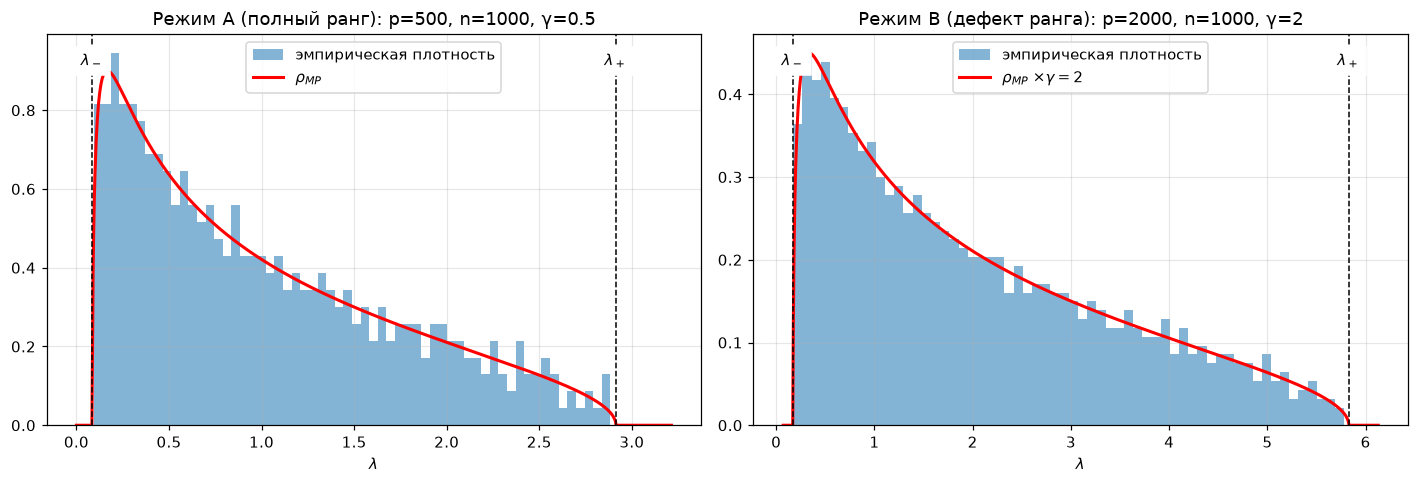

In [3]:
n = 1000
regimes = {"A (полный ранг)": 500, "B (дефект ранга)": 2000}
results_1 = []

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, p) in zip(axes, regimes.items()):
    gamma = p / n
    eigs = white_noise_spectrum(p, n)
    tol = zero_threshold(eigs, (p, n))
    nonzero = eigs[eigs > tol]
    lam_minus, lam_plus = mp_edges(gamma)
    scale = max(gamma, 1.0)  # gamma при gamma > 1, иначе 1

    grid = np.linspace(max(lam_minus - 0.1, 1e-4), lam_plus + 0.3, 1000)
    ax.hist(nonzero, bins=60, density=True, alpha=0.55, label="эмпирическая плотность")
    ax.plot(grid, scale * mp_density(grid, gamma), "r", lw=2,
            label=rf"$\rho_{{MP}}$" + (rf" $\times\gamma={gamma:g}$" if scale != 1 else ""))
    for x, lab in [(lam_minus, r"$\lambda_-$"), (lam_plus, r"$\lambda_+$")]:
        ax.axvline(x, color="k", ls="--", lw=1)
        ax.text(x, ax.get_ylim()[1] * 0.92, lab, ha="center", backgroundcolor="w")
    ax.set_title(f"Режим {name}: p={p}, n={n}, γ={gamma:g}")
    ax.set_xlabel(r"$\lambda$")
    ax.legend()

    n_zero = (eigs <= tol).sum()
    results_1.append((name, gamma, lam_minus, lam_plus, nonzero.min(), nonzero.max(), n_zero))
    if n_zero:
        print(f"{name}: tol = {tol:.2e}, нулевых: {n_zero} (ожидалось p-n = {p - n}), "
              f"max|нулевых| = {np.abs(eigs[eigs <= tol]).max():.1e}, "
              f"из них отрицательных: {(eigs < 0).sum()}")
plt.tight_layout()
plt.show()

In [4]:
print(f"{'Режим':<18}{'γ':>5}{'λ- теор':>10}{'λ̂min':>10}{'λ+ теор':>10}{'λ̂max':>10}{'λ̂max-λ+':>11}{'нулей':>7}")
for name, gamma, lm, lp, emin, emax, nz in results_1:
    print(f"{name:<18}{gamma:>5g}{lm:>10.4f}{emin:>10.4f}{lp:>10.4f}{emax:>10.4f}{emax - lp:>+11.4f}{nz:>7}")

Режим                 γ   λ- теор     λ̂min   λ+ теор     λ̂max   λ̂max-λ+  нулей
A (полный ранг)     0.5    0.0858    0.0928    2.9142    2.8841    -0.0301      0
B (дефект ранга)      2    0.1716    0.1734    5.8284    5.7837    -0.0448   1000


### 1.3. Флуктуации края спектра и случай $\gamma = 1$

Проверим две вещи на $p = n$:
* $\mathbb E\,\hat\lambda_{\max}\to\lambda_+ = (1+1)^2 = 4$;
* флуктуации $\hat\lambda_{\max}$ вокруг $\lambda_+$ имеют масштаб $n^{-2/3}$ (закон Трейси–Видома), т.е. величина
  $n^{2/3}(\hat\lambda_{\max}-\lambda_+)$ должна иметь одинаковое распределение при всех $n$, с предсказуемыми
  средним и разбросом.

Прогноз TW: n^(2/3)·(mean-4) = -3.04, n^(2/3)·std = 3.20

   n=p  mean λ̂max      std  n^(2/3)·(mean-4)  n^(2/3)·std  доля λ̂max>4
   100      3.8259   0.1524            -3.751        3.284          0.12
   200      3.8955   0.0877            -3.575        2.999          0.07
   400      3.9249   0.0517            -4.080        2.809          0.05
   800      3.9639   0.0379            -3.110        3.265          0.15
  1600      3.9813   0.0224            -2.552        3.068          0.23


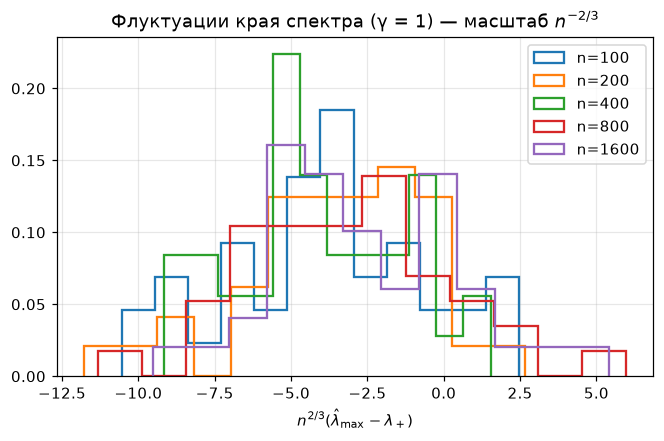

In [5]:
def top_eig_white(p, n, rng=rng):
    # Только максимальное собственное число 1/n XX^T через старшее сингулярное число X
    X = rng.standard_normal((p, n))
    s = svds(X, k=1, return_singular_vectors=False)
    return s[0] ** 2 / n


sizes = [100, 200, 400, 800, 1600]
reps = 40
lam_max = {m: np.array([top_eig_white(m, m) for _ in range(reps)]) for m in sizes}

# Теория Трейси–Видома для γ = 1: λ̂max ≈ 4 + σ_n·TW1, σ_n = 2·2^(1/3)·n^(-2/3)
TW1_MEAN, TW1_STD = -1.2065, 1.2680
tw_scale = 2 * 2 ** (1 / 3)
print(f"Прогноз TW: n^(2/3)·(mean-4) = {tw_scale * TW1_MEAN:.2f}, n^(2/3)·std = {tw_scale * TW1_STD:.2f}\n")
print(f"{'n=p':>6}{'mean λ̂max':>12}{'std':>9}{'n^(2/3)·(mean-4)':>18}{'n^(2/3)·std':>13}{'доля λ̂max>4':>14}")
for m in sizes:
    lm = lam_max[m]
    print(f"{m:>6}{lm.mean():>12.4f}{lm.std():>9.4f}{m ** (2 / 3) * (lm.mean() - 4):>18.3f}"
          f"{m ** (2 / 3) * lm.std():>13.3f}{(lm > 4).mean():>14.2f}")

fig, ax = plt.subplots(figsize=(7, 4))
for m in sizes:
    ax.hist(m ** (2 / 3) * (lam_max[m] - 4), bins=12, histtype="step", lw=1.5, density=True, label=f"n={m}")
ax.set_xlabel(r"$n^{2/3}(\hat\lambda_{\max}-\lambda_+)$")
ax.set_title("Флуктуации края спектра (γ = 1) — масштаб $n^{-2/3}$")
ax.legend()
plt.show()

### 1.4. Анализ результатов задания 1

**Совпали ли границы точно?** Нет, но очень близко (таблица выше): отклонения порядка $10^{-2}$.
Закон МП — *асимптотический* (при $p,n\to\infty$), а у нас конечные $p,n$. Края спектра — самые «шумные» места:
там плотность падает до нуля, и на каждой реализации крайние собственные числа заметно гуляют.

**Про $\hat\lambda_{\max}$ относительно $\lambda_+$.** В задании предполагается, что эмпирический максимум систематически
правее $\lambda_+$. Наш эксперимент показывает более тонкую картину: в обоих режимах п. 1.2 и в среднем по 40 повторам
в п. 1.3 $\hat\lambda_{\max}$ оказывается **чуть левее** $\lambda_+$, а правее — лишь в 5–25% реализаций (в среднем около 12%).
Это ровно то, что предсказывает теория:
* флуктуации старшего собственного числа описываются **распределением Трейси–Видома** $TW_1$ (для вещественных матриц):
  $\hat\lambda_{\max}\approx\lambda_+ + \sigma_n\cdot TW_1$, где $\sigma_n\sim n^{-2/3}$ (для $\gamma=1$: $\sigma_n = 2^{4/3}n^{-2/3}$);
* у $TW_1$ среднее $\approx-1.21$ (отрицательное!) и стандартное отклонение $\approx1.27$, распределение асимметрично с
  тяжёлым правым хвостом. Поэтому в среднем максимум недотягивает до $\lambda_+$ на $\approx3.05\,n^{-2/3}$, но регулярно
  «выскакивает» за край. Таблица п. 1.3 совпадает с прогнозом TW: $n^{2/3}(\text{mean}-4)\approx-3$, $n^{2/3}\text{std}\approx3.2$
  при всех $n$ — значит, масштаб $n^{-2/3}$ подтверждён.
* Почему «правее» — частая интуиция: максимум из огромного числа направлений *может* превысить предельный край,
  а на гистограмме эмпирическая плотность у края «размазана» за $\lambda_+$ (нет резкого обрыва, как у предельной кривой).
  Важный практический вывод: выход $\hat\lambda_{\max}$ за $\lambda_+$ на величину порядка $\sigma_n$ **ещё не означает сигнал** —
  нужен порог с запасом на TW (этим мы воспользуемся в задании 2).

Аналогично $\hat\lambda_{\min}$ чуть правее $\lambda_-$ (нижний край тоже «мягкий» при $\gamma\neq1$). Нулей в режиме B ровно
$p-n=1000$, и около половины из них численно отрицательны — именно поэтому `eigs > 0` не подходит.

**Почему при $p=n$ максимальная дисперсия по первой ГК стремится к 4, хотя истинная везде равна 1?**
* *Статистически:* $\hat\lambda_1 = \max_{\|u\|=1} u^T\hat\Sigma u$ — это максимум выборочной дисперсии по **всем** направлениям.
  Каждая отдельная фиксированная проекция $u^T\hat\Sigma u$ действительно $\approx 1$ (с ошибкой $\sim\sqrt{2/n}$), но
  направлений в $\mathbb R^p$ экспоненциально много, и максимум из огромного числа слабо зависимых «почти единиц»
  систематически смещён вверх. Ошибки оценки $p(p+1)/2$ элементов ковариации складываются: каждый элемент ошибается на
  $\sim1/\sqrt n$, а норма матрицы ошибок растёт как $\sqrt{p/n}$ — не стремится к нулю, если $p\sim n$.
  Формально: $\|\hat\Sigma - I\|\to(1+\sqrt\gamma)^2-1 = 2\sqrt\gamma+\gamma$, при $\gamma=1$ это 3.
* *Геометрически:* $n$ точек в $p=n$ измерениях — это «тонкое облако». Выборочная ковариация «подгоняется» под
  конкретные точки: PCA находит направление, вдоль которого точки *случайно* разбросаны сильнее, и одновременно
  направления, где разброс почти нулевой ($\lambda_-=0$ при $\gamma=1$). Изотропный шар превращается в вытянутый эллипсоид
  с полуосями от $0$ до $2\sigma$ (дисперсии от 0 до 4). Среднее при этом сохраняется: $\frac1p\operatorname{tr}\hat\Sigma\to1$ —
  дисперсия не появляется из ниоткуда, а **перераспределяется** между осями.
* *Вывод для практики:* в высокой размерности «главные компоненты» с собственными числами внутри $[\lambda_-,\lambda_+]$
  — артефакт, а не структура. Это и есть «иллюзия шума» из названия работы.

---
## Задание 2. Фазовый переход BBP: слепота PCA и калибровка искажений

Модель одиночного шипа: $\Sigma = I_p+\theta v_1v_1^T$, $v_1=e_1$, $p=1500$, $n=3000$, $\gamma=0.5$, $\theta_c=\sqrt\gamma\approx0.7071$.

### 2.1. Генерация spiked-модели
$(I+\theta e_1e_1^T)^{1/2} = \operatorname{diag}(\sqrt{1+\theta},1,\dots,1)$, поэтому умножение на неё — это просто
масштабирование первой строки $X$ в $\sqrt{1+\theta}$ раз (без построения $p\times p$ матрицы).

In [6]:
p2, n2 = 1500, 3000
gamma2 = p2 / n2
theta_c = np.sqrt(gamma2)
lam_minus2, lam_plus2 = mp_edges(gamma2)
print(f"γ = {gamma2}, θc = {theta_c:.4f}, λ- = {lam_minus2:.4f}, λ+ = {lam_plus2:.4f}")


def spiked_data(theta, p=p2, n=n2, rng=rng):
    Y = rng.standard_normal((p, n))
    Y[0] *= np.sqrt(1 + theta)  # (I + θ e1 e1^T)^{1/2} X
    return Y


def top_component(Y):
    # Старшая пара (λ̂1, v̂1) матрицы 1/n YY^T через старшее сингулярное разложение Y/√n:
    # Y/√n = U S V^T  =>  1/n YY^T = U S^2 U^T, т.е. λ̂1 = s1^2, v̂1 = u1
    n = Y.shape[1]
    u, s, _ = svds(Y / np.sqrt(n), k=1)
    return s[0] ** 2, u[:, 0]

γ = 0.5, θc = 0.7071, λ- = 0.0858, λ+ = 2.9142


### 2.2. Ловушка с порядком собственных чисел и проверка ускорения

`numpy.linalg.eigh` возвращает собственные числа **по возрастанию**, поэтому `w[0]`, `V[:, 0]` — это *младшая* пара
(≈ $\lambda_-$), а главная компонента — `w[-1]`, `V[:, -1]`. Покажем ошибку и сравним скорость полного разложения
с поиском одной старшей сингулярной тройки (`svds`, метод Ланцоша — нужно только несколько умножений матрицы на вектор).

In [7]:
Y = spiked_data(theta=2.0)
t0 = time.perf_counter()
w, V = np.linalg.eigh(Y @ Y.T / n2)
t_eigh = time.perf_counter() - t0
t0 = time.perf_counter()
lam1, v1_hat = top_component(Y)
t_svds = time.perf_counter() - t0

print(f"eigh, первый элемент 'в лоб': λ = {w[0]:.4f}, |<v,e1>|² = {V[0, 0] ** 2:.2e}   <- это λ_min!")
print(f"eigh, правильный срез [-1]:  λ = {w[-1]:.4f}, |<v,e1>|² = {V[0, -1] ** 2:.4f}")
print(f"svds (k=1):                  λ = {lam1:.4f}, |<v,e1>|² = {v1_hat[0] ** 2:.4f}")
print(f"Время: eigh (с построением ковариации) {t_eigh:.2f} c, svds {t_svds:.2f} c")

eigh, первый элемент 'в лоб': λ = 0.0864, |<v,e1>|² = 6.42e-05   <- это λ_min!
eigh, правильный срез [-1]:  λ = 3.7107, |<v,e1>|² = 0.7053
svds (k=1):                  λ = 3.7107, |<v,e1>|² = 0.7053
Время: eigh (с построением ковариации) 0.44 c, svds 0.17 c


### 2.3. Сканирование по $\theta\in[0.1, 2.5]$, усреднение по $M=10$ генерациям

Теоретические кривые строим **кусочно**: формула $(1+\theta)(1+\gamma/\theta)$ справедлива только при $\theta>\theta_c$.
При $\theta\to0$ она уходит в $+\infty$ (член $\gamma/\theta$), что физически бессмысленно: в докритической области
старшее собственное число просто сидит на краю балка $\lambda_+$. Заметим, что в точке $\theta_c$ обе ветви сшиваются
непрерывно: $(1+\sqrt\gamma)(1+\sqrt\gamma) = \lambda_+$.

In [8]:
def bbp_lambda(theta, gamma):
    theta = np.asarray(theta, dtype=float)
    supercrit = theta > np.sqrt(gamma)
    safe = np.where(supercrit, theta, 1.0)  # чтобы не делить на малые θ в неиспользуемой ветви
    return np.where(supercrit, (1 + safe) * (1 + gamma / safe), (1 + np.sqrt(gamma)) ** 2)


def bbp_overlap(theta, gamma):
    theta = np.asarray(theta, dtype=float)
    supercrit = theta > np.sqrt(gamma)
    safe = np.where(supercrit, theta, 1.0)
    return np.where(supercrit, (1 - gamma / safe ** 2) / (1 + gamma / safe), 0.0)


thetas = np.round(np.arange(0.1, 2.5 + 1e-9, 0.1), 1)
M = 10
lam1_runs = np.zeros((len(thetas), M))
overlap_runs = np.zeros((len(thetas), M))

t0 = time.perf_counter()
for i, theta in enumerate(thetas):
    for m in range(M):
        lam1, v1_hat = top_component(spiked_data(theta))
        lam1_runs[i, m] = lam1
        overlap_runs[i, m] = v1_hat[0] ** 2  # <v̂1, e1>^2
print(f"Готово за {time.perf_counter() - t0:.1f} c")

lam1_mean, lam1_std = lam1_runs.mean(1), lam1_runs.std(1)
ov_mean, ov_std = overlap_runs.mean(1), overlap_runs.std(1)

Готово за 107.8 c


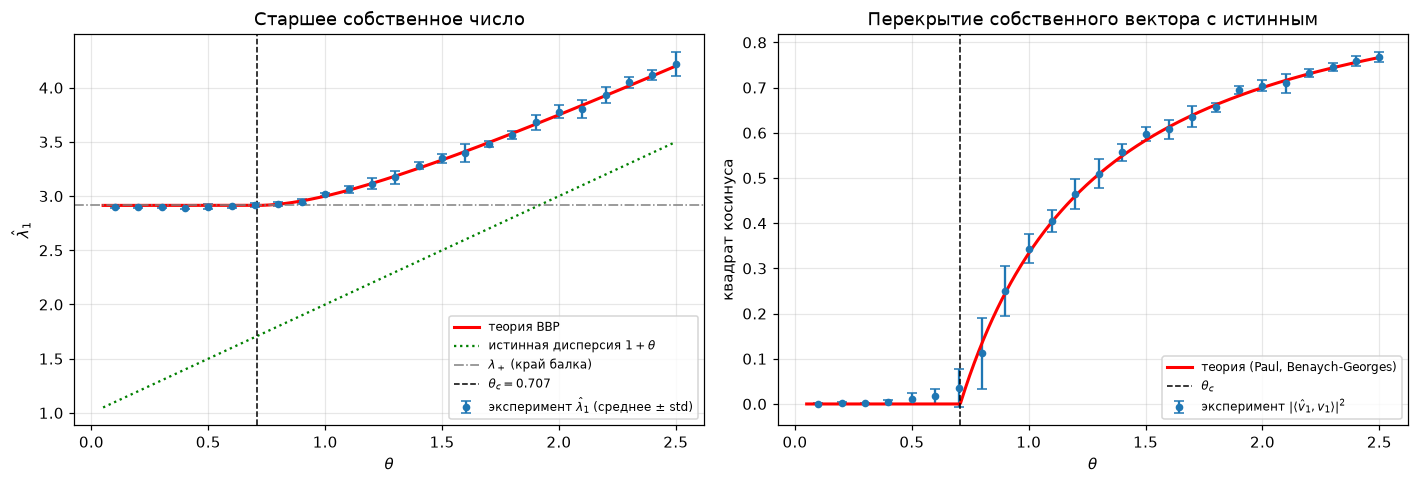

In [9]:
theta_grid = np.linspace(0.05, 2.5, 500)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.errorbar(thetas, lam1_mean, yerr=lam1_std, fmt="o", ms=4, capsize=3, label=r"эксперимент $\hat\lambda_1$ (среднее ± std)")
ax.plot(theta_grid, bbp_lambda(theta_grid, gamma2), "r", lw=2, label="теория BBP")
ax.plot(theta_grid, 1 + theta_grid, "g:", lw=1.5, label=r"истинная дисперсия $1+\theta$")
ax.axhline(lam_plus2, color="gray", ls="-.", lw=1, label=r"$\lambda_+$ (край балка)")
ax.axvline(theta_c, color="k", ls="--", lw=1, label=rf"$\theta_c={theta_c:.3f}$")
ax.set_xlabel(r"$\theta$"); ax.set_ylabel(r"$\hat\lambda_1$")
ax.set_title("Старшее собственное число")
ax.legend(fontsize=8)

ax = axes[1]
ax.errorbar(thetas, ov_mean, yerr=ov_std, fmt="o", ms=4, capsize=3, label=r"эксперимент $|\langle\hat v_1,v_1\rangle|^2$")
ax.plot(theta_grid, bbp_overlap(theta_grid, gamma2), "r", lw=2, label="теория (Paul, Benaych-Georges)")
ax.axvline(theta_c, color="k", ls="--", lw=1, label=rf"$\theta_c$")
ax.set_xlabel(r"$\theta$"); ax.set_ylabel("квадрат косинуса")
ax.set_title("Перекрытие собственного вектора с истинным")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Что видно:**
* При $\theta<\theta_c$ $\hat\lambda_1$ прилипает к $\lambda_+\approx2.914$, а перекрытие $\approx0$ (порядка $1/p$):
  PCA **слеп** — найденная «главная компонента» — случайное направление шума.
* При $\theta>\theta_c$ собственное число отрывается от балка, вектор начинает указывать на сигнал.
* Красная кривая (BBP) везде **выше** зелёной ($1+\theta$): наблюдаемая дисперсия завышает истинную.
* Около $\theta_c$ эксперимент «сглаживает» излом: при конечных $p,n$ переход размыт на ширину $\sim n^{-1/3}$,
  поэтому в окрестности порога точки чуть отклоняются от предельной кривой.

### 2.4. Калибровка сигнала (инверсия BBP)

Из $\lambda=(1+\theta)(1+\gamma/\theta)$, обозначив $t=1+\theta$, получаем квадратное уравнение
$t^2-(\lambda+1-\gamma)t+\lambda=0$, больший корень которого и даёт формулу из задания.
Дискриминант $(\lambda+1-\gamma)^2-4\lambda = \big(\lambda-\lambda_-\big)\big(\lambda-\lambda_+\big)$, т.е. формула
имеет вещественное решение **только при** $\lambda\ge\lambda_+$. Это естественный guard clause.

Для конечных выборок добавляем запас на флуктуации края Трейси–Видома: порог $\lambda_+ + q_{0.99}\,\sigma_{TW}$,
где $\sigma_{TW} = \frac1n(\sqrt n+\sqrt p)\big(\tfrac1{\sqrt n}+\tfrac1{\sqrt p}\big)^{1/3}$ (Johnstone, 2001), $q_{0.99}(TW_1)\approx2.02$.
Иначе чистый шум с вероятностью ~50% выдавал бы «сигнал».

In [10]:
TW1_Q99 = 2.02  # 99%-квантиль распределения Трейси–Видома TW1


def detection_threshold(p, n):
    gamma = p / n
    sigma_tw = (np.sqrt(n) + np.sqrt(p)) * (1 / np.sqrt(n) + 1 / np.sqrt(p)) ** (1 / 3) / n
    return (1 + np.sqrt(gamma)) ** 2 + TW1_Q99 * sigma_tw


def calibrate_theta(lam1, p=p2, n=n2):
    # Возвращает несмещённую оценку θ̂ или вердикт об отсутствии сигнала
    gamma = p / n
    if lam1 <= detection_threshold(p, n):
        return "Сигнал отсутствует или находится ниже предела детектирования"
    b = lam1 + 1 - gamma
    return (b + np.sqrt(b ** 2 - 4 * lam1)) / 2 - 1


print(f"Порог детектирования: λ̂1 > {detection_threshold(p2, n2):.4f}  (λ+ = {lam_plus2:.4f})\n")
for lam in [2.9, 2.95, 3.0, 3.75, 5.0]:
    res = calibrate_theta(lam)
    print(f"λ̂1 = {lam:<5} ->", f"θ̂ = {res:.4f}" if isinstance(res, float) else res)

Порог детектирования: λ̂1 > 2.9365  (λ+ = 2.9142)

λ̂1 = 2.9   -> Сигнал отсутствует или находится ниже предела детектирования
λ̂1 = 2.95  -> θ̂ = 0.8851
λ̂1 = 3.0   -> θ̂ = 1.0000
λ̂1 = 3.75  -> θ̂ = 2.0000
λ̂1 = 5.0   -> θ̂ = 3.3508


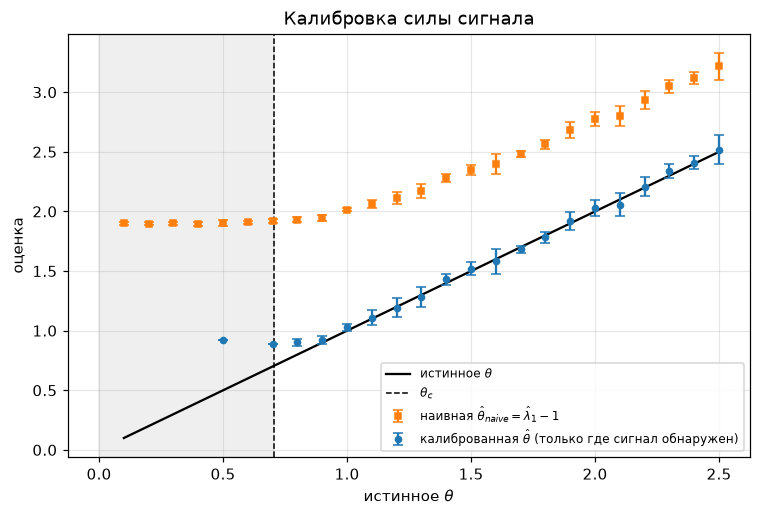

    θ   наивная   калибр.  обнаружен (из M)
  0.1     1.900       nan           0/10
  0.2     1.898       nan           0/10
  0.3     1.901       nan           0/10
  0.4     1.894       nan           0/10
  0.5     1.903     0.919           1/10
  0.6     1.907       nan           0/10
  0.7     1.919     0.888           2/10
  0.8     1.931     0.901           3/10
  0.9     1.947     0.921           6/10
  1.0     2.015     1.029          10/10
  1.1     2.062     1.110          10/10
  1.2     2.115     1.194          10/10
  1.3     2.173     1.281          10/10
  1.4     2.282     1.432          10/10
  1.5     2.350     1.521          10/10
  1.6     2.400     1.583          10/10
  1.7     2.481     1.684          10/10
  1.8     2.563     1.782          10/10
  1.9     2.680     1.919          10/10
  2.0     2.778     2.032          10/10
  2.1     2.801     2.057          10/10
  2.2     2.935     2.208          10/10
  2.3     3.050     2.335          10/10
  2.4     3.1

In [11]:
theta_naive = lam1_runs - 1
theta_cal = np.array([[c if isinstance(c := calibrate_theta(l), float) else np.nan for l in row] for row in lam1_runs])
detected = ~np.isnan(theta_cal)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thetas, thetas, "k-", lw=1.5, label=r"истинное $\theta$")
ax.errorbar(thetas, theta_naive.mean(1), yerr=theta_naive.std(1), fmt="s", ms=4, capsize=3, color="tab:orange",
            label=r"наивная $\hat\theta_{naive}=\hat\lambda_1-1$")
cal_mean = np.array([np.nanmean(r) if np.any(~np.isnan(r)) else np.nan for r in theta_cal])
cal_std = np.array([np.nanstd(r) if np.any(~np.isnan(r)) else np.nan for r in theta_cal])
ax.errorbar(thetas, cal_mean, yerr=cal_std, fmt="o", ms=4, capsize=3, color="tab:blue",
            label=r"калиброванная $\hat\theta$ (только где сигнал обнаружен)")
ax.axvline(theta_c, color="k", ls="--", lw=1, label=r"$\theta_c$")
ax.axvspan(0, theta_c, color="gray", alpha=0.12)
ax.set_xlabel(r"истинное $\theta$"); ax.set_ylabel("оценка")
ax.set_title("Калибровка силы сигнала")
ax.legend(fontsize=8)
plt.show()

print(f"{'θ':>5}{'наивная':>10}{'калибр.':>10}{'обнаружен (из M)':>18}")
for th, nv, cv, d in zip(thetas, theta_naive.mean(1), cal_mean, detected.sum(1)):
    print(f"{th:>5.1f}{nv:>10.3f}{cv:>10.3f}{d:>12}/{M}")

**Выводы задания 2:**
* Порог $\theta_c=\sqrt{p/n}$ — фундаментальный предел: ниже него никакой спектральный метод не отличит сигнал от шума,
  сколько бы мы ни «смотрели» на матрицу. Чтобы видеть слабее сигналы, нужно больше данных ($n\uparrow\Rightarrow\gamma\downarrow$).
* Наивная оценка $\hat\lambda_1-1$ систематически завышена (на $\gamma(1+\theta)/\theta$; особенно сильно рядом с порогом)
  и в докритической зоне показывает «сигнал» ≈ 1.9 даже при $\theta=0.1$ (это просто $\lambda_+-1$).
* Калиброванная оценка ложится на диагональ, а ниже порога честно отвечает «сигнала нет».
  Вблизи $\theta_c$ часть реализаций не проходит порог — это зона, где сигнал на конечной выборке неотличим от флуктуаций TW
  (единичные срабатывания чуть ниже $\theta_c$ — тоже эффект конечного $n$: переход размыт, и слабый шип немного
  приподнимает край балка).

---
## Задание 3. Спектральная диагностика слоёв ResNet-18 (теория Мартина–Махони)

### 3.1. Извлечение матриц и быстрый спектр

Для $W\in\mathbb R^{M\times K}$ и $N=\max(M,K)$: если $W=U\,\mathrm{diag}(s)\,V^T$, то
$W^TW = V\,\mathrm{diag}(s^2)\,V^T$ и $WW^T=U\,\mathrm{diag}(s^2)\,U^T$. Значит **ненулевые** собственные числа обеих матриц
$S$ одинаковы и равны $\lambda_i = s_i^2/N$, их ровно $\min(M,K)$. Считаем сингулярные числа $W$ (матрица $512\times4608$)
и не строим $4608\times4608$ с тысячами машинных нулей. Эквивалентный вариант — перемножать в «коротком» порядке:
$\frac1N WW^T$ размера $512\times512$.

In [12]:
import torch
import torchvision.models as models

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.eval()
params = dict(model.named_parameters())


def layer_matrix(name):
    # Conv2d (Cout, Cin, K, K) -> Cout x (Cin*K*K); Linear -> как есть
    w = params[name + ".weight"].detach().double().numpy()
    return w.reshape(w.shape[0], -1)


def esd(W):
    # Ненулевые собственные числа S = W^T W / N через сингулярные числа
    N = max(W.shape)
    s = np.linalg.svd(W, compute_uv=False)
    lam = s ** 2 / N
    return np.sort(lam[lam > lam.max() * max(W.shape) * np.finfo(float).eps])


W = layer_matrix("layer4.1.conv2")
t0 = time.perf_counter(); lam_fast = esd(W); t_fast = time.perf_counter() - t0
t0 = time.perf_counter(); lam_full = np.linalg.eigvalsh(W.T @ W / max(W.shape)); t_full = time.perf_counter() - t0
print(f"layer4.1.conv2: W {W.shape}, ненулевых λ: {lam_fast.size}")
print(f"через SVD: {t_fast:.3f} c; полная 4608x4608: {t_full:.2f} c, "
      f"из них |λ| < 1e-10: {(np.abs(lam_full) < 1e-10).sum()}")
print("max расхождение старших 512 λ:", np.abs(np.sort(lam_full)[-lam_fast.size:] - lam_fast).max())

layer4.1.conv2: W (512, 4608), ненулевых λ: 512
через SVD: 0.503 c; полная 4608x4608: 8.32 c, из них |λ| < 1e-10: 4096
max расхождение старших 512 λ: 3.469446951953614e-18


### 3.2. Подгонка степенного закона для `layer4.1.conv2`

#### Наивный МНК по гистограмме
Строим $\ln\rho(\lambda)$ против $\ln\lambda$ по бинам гистограммы правее её пика, наклон $=-\alpha$.
Проверяем, как оценка зависит от числа бинов, для линейных и логарифмических бинов.

  bins   α (лин. бины)   α (лог. бины)
    10           2.205           1.287
    20           1.692           1.374
    30           1.408           1.246
    50           1.286           1.169
    80           1.095           1.079
   120           1.019           0.991
   200           0.881           0.945


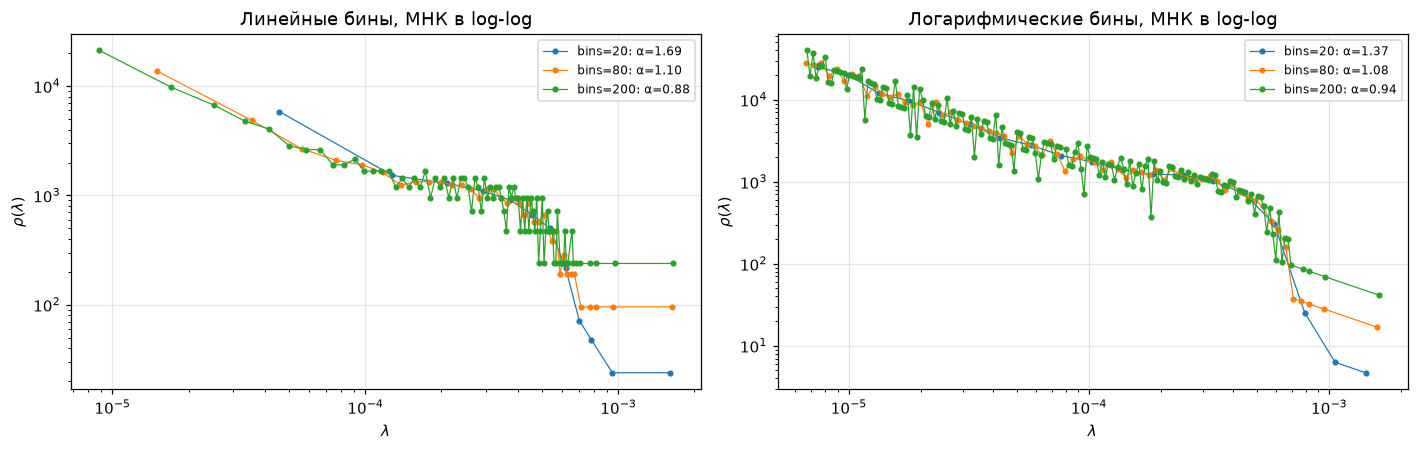

In [13]:
def ols_alpha(lam, bins, log_bins=False):
    edges = np.geomspace(lam.min(), lam.max(), bins + 1) if log_bins else np.linspace(lam.min(), lam.max(), bins + 1)
    counts, edges = np.histogram(lam, bins=edges)
    dens = counts / (counts.sum() * np.diff(edges))  # плотность = count / (N * ширина бина)
    centers = np.sqrt(edges[:-1] * edges[1:]) if log_bins else (edges[:-1] + edges[1:]) / 2
    mask = (np.arange(bins) >= np.argmax(dens)) & (counts > 0)  # правее пика, без пустых бинов (ln 0)
    slope, _ = np.polyfit(np.log(centers[mask]), np.log(dens[mask]), 1)
    return -slope, centers, dens, mask


bin_list = [10, 20, 30, 50, 80, 120, 200]
print(f"{'bins':>6}{'α (лин. бины)':>16}{'α (лог. бины)':>16}")
for b in bin_list:
    print(f"{b:>6}{ols_alpha(lam_fast, b)[0]:>16.3f}{ols_alpha(lam_fast, b, log_bins=True)[0]:>16.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, log_bins in zip(axes, [False, True]):
    for b in [20, 80, 200]:
        a, c, d, m = ols_alpha(lam_fast, b, log_bins)
        ax.loglog(c[m], d[m], "o-", ms=3, lw=0.8, label=f"bins={b}: α={a:.2f}")
    ax.set_title(("Логарифмические" if log_bins else "Линейные") + " бины, МНК в log-log")
    ax.set_xlabel(r"$\lambda$"); ax.set_ylabel(r"$\rho(\lambda)$")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Почему МНК здесь несостоятелен:**
* *Линейные бины.* В хвосте степенного закона точек мало, и при линейном шаге почти все правые бины содержат 0 или 1
  собственное число. Пустые бины приходится выбрасывать ($\ln0=-\infty$) — это систематический сдвиг; бины с 1 точкой
  дают дискретный «пол» плотности $1/(N\Delta)$. Хвост представлен шумными «ступеньками», а большинство точек регрессии
  сидит в нехвостовой области. При смене `bins` меняется и пол, и набор выброшенных бинов → $\alpha$ скачет.
* *Логарифмические бины.* Ширина бина растёт пропорционально $\lambda$, поэтому в каждый попадает сопоставимая
  вероятностная мера: $\int_{\lambda}^{c\lambda}\lambda^{-\alpha}d\lambda\propto\lambda^{1-\alpha}$ — убывает гораздо медленнее,
  чем при линейных бинах. Пустых бинов меньше, оценка стабильнее, но это всё ещё МНК (обязательно делить на ширину бина!).
* *Где начинается хвост?* МНК не умеет выбирать $\lambda_{\min}$: регрессия по всем бинам правее пика смешивает балк
  и хвост, поэтому даже логарифмические бины дают $\alpha\approx1$–$1.4$ — далеко от MLE-оценки ниже.
* *Принципиально:* МНК предполагает независимые гауссовы ошибки одинаковой дисперсии. После логарифмирования
  пуассоновского счёта ошибки гетероскедастичны (относительная ошибка $\sim1/\sqrt{\text{count}}$), а точки гистограммы
  зависимы через нормировку. Оценка смещена, нет корректных доверительных интервалов, результат зависит от
  произвольного выбора бинов (Clauset, Shalizi, Newman, 2009). Правильный метод — максимальное правдоподобие.

#### MLE (оценщик Хилла) с выбором $\lambda_{\min}$ по Колмогорову–Смирнову
Для каждого кандидата $\lambda_{\min}$ из выборки: оцениваем $\alpha$ по Хиллу на хвосте $\lambda\ge\lambda_{\min}$,
считаем $D_{KS}=\max|F_{\text{emp}}-F_{\text{теор}}|$ и берём $\lambda_{\min}$ с минимальным $D_{KS}$.

In [14]:
def hill_alpha(tail, lam_min):
    return 1 + tail.size / np.log(tail / lam_min).sum()


def fit_power_law(lam, min_tail=10):
    # MLE-оценка α с подбором λ_min минимизацией статистики КС; возвращает dict или None
    lam = np.sort(np.asarray(lam, dtype=float))
    if lam.size < min_tail + 1:
        return None
    best = None
    for i in range(lam.size - min_tail + 1):
        lam_min = lam[i]
        tail = lam[i:]
        if tail[-1] <= lam_min:
            continue
        alpha = hill_alpha(tail, lam_min)
        cdf_theory = 1 - (tail / lam_min) ** (-(alpha - 1))
        k = tail.size
        # КС-расстояние до ступенчатой эмпирической CDF (по обе стороны ступеньки)
        d_ks = max(np.max(np.arange(1, k + 1) / k - cdf_theory), np.max(cdf_theory - np.arange(k) / k))
        if best is None or d_ks < best["D"]:
            best = {"alpha": alpha, "lam_min": lam_min, "D": d_ks, "n_tail": k}
    return best


fit = fit_power_law(lam_fast)
print(f"layer4.1.conv2: α = {fit['alpha']:.3f}, λ_min = {fit['lam_min']:.3e}, "
      f"D_KS = {fit['D']:.3f}, точек в хвосте: {fit['n_tail']} из {lam_fast.size}")

# Чувствительность к порогу: α при произвольно выбранных λ_min — поэтому порог нужно выбирать по КС, а не «на глаз»
for q in [0.5, 0.7, 0.8, 0.9]:
    lm = np.quantile(lam_fast, q)
    print(f"  λ_min = квантиль {q:.1f}: α = {hill_alpha(lam_fast[lam_fast >= lm], lm):.3f}")

layer4.1.conv2: α = 5.828, λ_min = 4.740e-04, D_KS = 0.064, точек в хвосте: 44 из 512
  λ_min = квантиль 0.5: α = 1.964
  λ_min = квантиль 0.7: α = 3.067
  λ_min = квантиль 0.8: α = 3.981
  λ_min = квантиль 0.9: α = 5.469


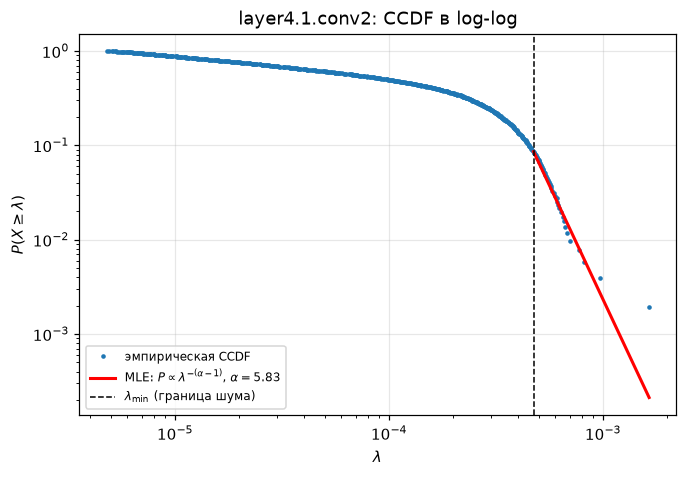

In [15]:
def plot_ccdf(ax, lam, fit, title):
    lam = np.sort(lam)
    ccdf = 1 - np.arange(lam.size) / lam.size  # P(X >= λ_i)
    ax.loglog(lam, ccdf, ".", ms=4, label="эмпирическая CCDF")
    if fit is not None:
        x = np.geomspace(fit["lam_min"], lam.max(), 100)
        frac = fit["n_tail"] / lam.size  # хвост содержит только долю всей массы
        ax.loglog(x, frac * (x / fit["lam_min"]) ** (-(fit["alpha"] - 1)), "r-", lw=2,
                  label=rf"MLE: $P\propto\lambda^{{-(\alpha-1)}}$, $\alpha={fit['alpha']:.2f}$")
        ax.axvline(fit["lam_min"], color="k", ls="--", lw=1, label=r"$\lambda_{\min}$ (граница шума)")
    ax.xaxis.set_minor_formatter(plt.NullFormatter())  # иначе подписи минорных делений слипаются
    ax.set_xlabel(r"$\lambda$"); ax.set_ylabel(r"$P(X\geq\lambda)$")
    ax.set_title(title)
    ax.legend(fontsize=8)


fig, ax = plt.subplots(figsize=(7, 4.5))
plot_ccdf(ax, lam_fast, fit, "layer4.1.conv2: CCDF в log-log")
plt.show()

CCDF (функция выживания) не требует бинов вообще: каждая точка — одно собственное число. Степенная плотность
$\rho\propto\lambda^{-\alpha}$ даёт CCDF $\propto\lambda^{-(\alpha-1)}$ — прямую линию в log-log с наклоном $-(\alpha-1)$.

Для `layer4.1.conv2` получаем $\alpha\approx5.8>4$: это слабо коррелированный слой (по HTSR — фаза Bulk-Decay /
«слабообученный»). Это согласуется с известными наблюдениями: в ResNet последние свёрточные слои огромные
($512\times4608$) и у них много «лишней» ёмкости, а реальный сигнал сидит в небольшом числе собственных чисел.

### 3.3. Диагностика патологий сети (слепой тест)

Формируем 4 тестовых слоя. Для рандомизированного слоя берём $\sigma$ равной стандартному отклонению исходных весов
этого слоя — так масштаб совпадает с обученным, а структура уничтожена.

In [16]:
def rank_k_approx(W, k):
    U, s, Vt = np.linalg.svd(W, full_matrices=False)
    s[k:] = 0.0
    return (U * s) @ Vt


W_l1 = layer_matrix("layer1.0.conv1")
test_layers = {
    "layer1.0.conv1 (рандом)": rng.normal(0.0, W_l1.std(), size=W_l1.shape),
    "layer2.0.conv1 (штатный)": layer_matrix("layer2.0.conv1"),
    "layer3.0.conv1 (коллапс)": rank_k_approx(layer_matrix("layer3.0.conv1"), k=2),
    "fc (выходной)": layer_matrix("fc"),
}

# Записываем изменённые веса обратно в модель, как требует задание
with torch.no_grad():
    for (name, Wt), lname in zip(test_layers.items(), ["layer1.0.conv1", "layer2.0.conv1", "layer3.0.conv1", "fc"]):
        p_ = params[lname + ".weight"]
        p_.copy_(torch.from_numpy(Wt).reshape(p_.shape).to(p_.dtype))

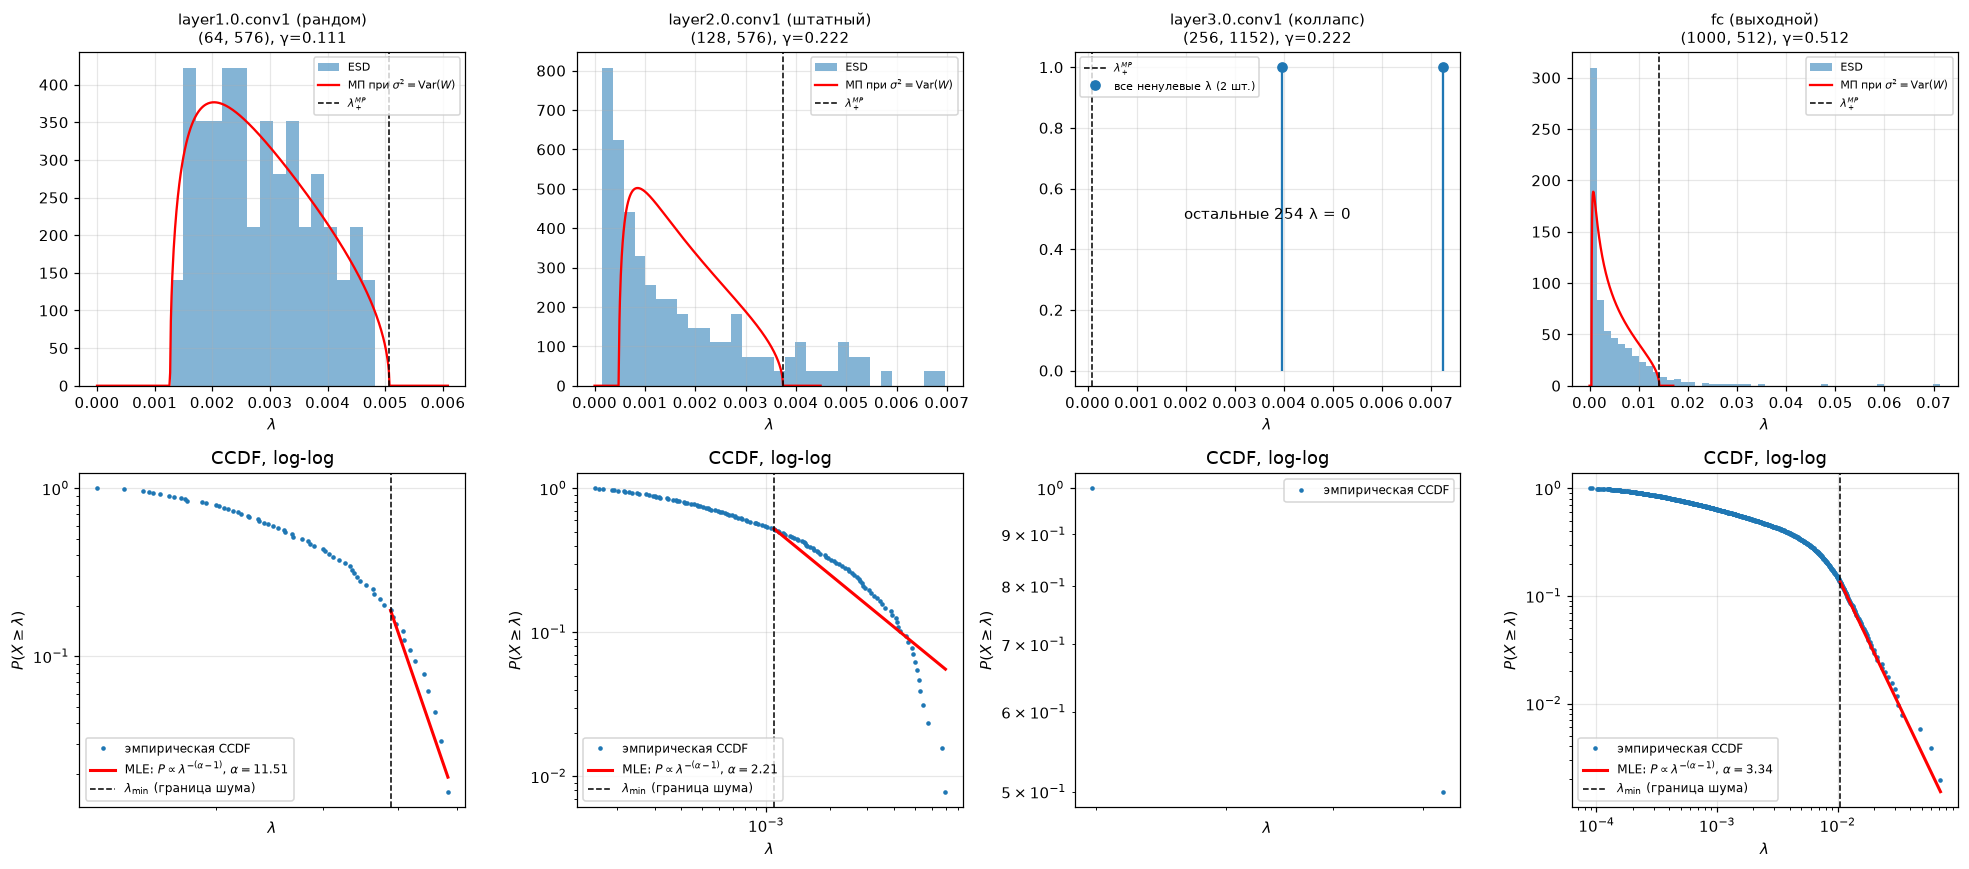

In [17]:
def stable_rank(lam):
    return lam.sum() / lam.max()


summary = []
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for j, (name, Wt) in enumerate(test_layers.items()):
    lam = esd(Wt)
    Mdim, Kdim = Wt.shape
    gamma = min(Mdim, Kdim) / max(Mdim, Kdim)
    sigma2 = Wt.var()  # дисперсия элементов -> масштаб балка МП
    lam_mp_minus, lam_mp_plus = mp_edges(gamma, sigma2)
    fit_j = fit_power_law(lam)
    n_out = int((lam > lam_mp_plus).sum())
    summary.append(dict(name=name, shape=Wt.shape, n_lam=lam.size, srank=stable_rank(lam),
                        alpha=fit_j["alpha"] if fit_j else np.nan, lam_max=lam.max(),
                        mp_plus=lam_mp_plus, n_out=n_out))

    ax = axes[0, j]
    if lam.size > 10:
        ax.hist(lam, bins=min(50, lam.size // 4), density=True, alpha=0.55, label="ESD")
        grid = np.linspace(1e-12, max(lam_mp_plus * 1.2, 0), 500)
        ax.plot(grid, mp_density(grid, gamma, sigma2), "r", lw=1.5, label=r"МП при $\sigma^2=\mathrm{Var}(W)$")
    else:
        ax.stem(lam, np.ones_like(lam), basefmt=" ", label=f"все ненулевые λ ({lam.size} шт.)")
        ax.text(0.5, 0.5, f"остальные {min(Wt.shape) - lam.size} λ = 0", transform=ax.transAxes, ha="center")
    ax.axvline(lam_mp_plus, color="k", ls="--", lw=1, label=r"$\lambda_+^{MP}$")
    ax.set_title(f"{name}\n{Wt.shape}, γ={gamma:.3f}", fontsize=10)
    ax.set_xlabel(r"$\lambda$")
    ax.legend(fontsize=7)

    plot_ccdf(axes[1, j], lam, fit_j, "CCDF, log-log")
plt.tight_layout()
plt.show()

In [18]:
print(f"{'слой':<26}{'форма':>13}{'#λ':>5}{'srank':>8}{'α (MLE)':>9}{'λmax':>11}{'λ+ МП':>11}{'#λ>λ+':>7}")
for s in summary:
    alpha = "не опр." if np.isnan(s["alpha"]) else f"{s['alpha']:.2f}"
    print(f"{s['name']:<26}{str(s['shape']):>13}{s['n_lam']:>5}{s['srank']:>8.2f}{alpha:>9}"
          f"{s['lam_max']:>11.2e}{s['mp_plus']:>11.2e}{s['n_out']:>7}")

слой                              форма   #λ   srank  α (MLE)       λmax      λ+ МП  #λ>λ+
layer1.0.conv1 (рандом)       (64, 576)   64   37.82    11.51   4.83e-03   5.07e-03      0
layer2.0.conv1 (штатный)     (128, 576)  128   31.78     2.21   6.97e-03   3.74e-03     18
layer3.0.conv1 (коллапс)    (256, 1152)    2    1.55  не опр.   7.25e-03   9.10e-05      2
fc (выходной)               (1000, 512)  512   34.60     3.34   7.14e-02   1.42e-02     35


#### Почему у рандомизированного слоя степенного хвоста нет (хотя `fit_power_law` вернул число)

Алгоритм MLE+КС **всегда** вернёт какое-то $\alpha$: он ищет лучший степенной закон, а не проверяет, существует ли он.
Для случайной матрицы с i.i.d. элементами дисперсии $\sigma^2$ теория МП утверждает: весь спектр лежит в
$[\lambda_-,\lambda_+]$, $\lambda_+=\sigma^2(1+\sqrt\gamma)^2$ (с поправкой Трейси–Видома $O(N^{-2/3})$). Проверка в таблице:
у `layer1.0.conv1 (рандом)` **ни одно** собственное число не выходит за $\lambda_+^{MP}$, $\lambda_{\max}\le\lambda_+$.
Степенной хвост — это по определению масса **за** пределами балка, простирающаяся на порядки величины; здесь весь
«хвост» — это правый край полукруга МП, сжатый в отрезок шириной меньше порядка величины. Поэтому полученное большое
$\alpha$ — артефакт подгонки к убывающему краю МП-плотности, а гистограмма идеально ложится на теоретическую кривую МП.

Для сравнения: у обученных слоёв десятки собственных чисел выходят за $\lambda_+^{MP}$, а $\lambda_{\max}$ в разы
больше края шума — это и есть корреляции, выученные при обучении.

#### Итоговый вывод: классификация Мартина–Махони (5+1 фаз)

| Фаза HTSR | Признаки |
|---|---|
| 1. Random-like | ESD = чистый балк МП, нет выбросов |
| 2. Bleeding-out | несколько λ чуть «просачиваются» за $\lambda_+$ |
| 3. Bulk+Spikes | балк МП + отдельные шипы (как в BBP) |
| 4. Bulk-Decay | балк расплывается, хвост слабый ($\alpha>4$) |
| 5. Heavy-Tailed | степенной хвост, $\alpha\in(2,4]$ — «зона Златовласки» |
| +1. Rank-Collapse | спектр вырожден, почти все λ = 0 |

| Слой | Диагноз |
|---|---|
| `layer1.0.conv1` (рандом) | **Фаза 1, Random-like — чистый белый шум.** Спектр совпадает с МП, $\lambda_{\max}\le\lambda_+$, srank высокий; $\alpha$ формально большой, но хвоста нет. |
| `layer2.0.conv1` (штатный) | **Фаза 5, Heavy-Tailed — «зона Златовласки».** $\alpha\approx2.2$, много λ за краем МП. Оптимальная неявная самoрегуляризация. |
| `layer3.0.conv1` (коллапс) | **Rank-Collapse.** Всего 2 ненулевых λ, srank ≈ 1, $\alpha$ не определён (2 точки — не распределение). Слой потерял почти всю вариативность. |
| `fc` (выходной) | **Фаза 5, Heavy-Tailed.** $\alpha\approx3.3\in(2,4]$ — хорошо обученный классификатор. |
| `layer4.1.conv2` (из п. 3.2) | **Фаза 4, Bulk-Decay** ($\alpha\approx5.8>4$) — слой обучен слабее/избыточен. |

Ключевая идея: всё это получено **без единого тестового примера** — только по весам. Шум даёт МП-балк,
выученная структура — тяжёлый хвост, деградация — схлопывание спектра.